# EDA analysis of training dataset

## Import of main libraries and loading the dataset

In [17]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_colwidth", 120)

df = pd.read_csv(Path("..") / "data" / "raw" / "bitext.csv")
df.shape, df.columns.tolist()

((26872, 5), ['flags', 'instruction', 'category', 'intent', 'response'])

## Basic information about dataset

According to Hugging face information, we have 5 columns with following meanings.


[Bitext Customer Support LLM Chatbot Training Dataset](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset): 26,872 synthetic customer-support requests labelled with <N> intents grouped into <M> categories.

### Columns

| Column | Description | Use in this project |
|---|---|---|
| `instruction` | User request text | Model input |
| `intent` | Fine-grained intent, e.g. `cancel_order` | Target |
| `category` | High-level group of the intent, e.g. `ORDER` | Returned by the API alongside the intent |
| `flags` | Language-variation tags, one or more letters per row, e.g. `BQZ` | Slice-level metrics, drift simulation |
| `response` | Reference assistant reply | Not used as a feature (not available at inference time) |

### Language-variation tags (`flags`)

| Tag | Variation | Example |
|---|---|---|
| B | Basic syntactic structure | activate my SIM card |
| I | Interrogative | can you activate my SIM card? |
| C | Coordinated structure | I have a new SIM card, what do I need to do to activate it? |
| N | Negation | I do not want this item, where to cancel my order? |
| M | Morphological variation | active / activated |
| L | Semantic variation (synonyms) | billing date / anniversary date |
| P | Politeness | could you help me activate my SIM card, please? |
| Q | Colloquial | can u activ8 my SIM? |
| W | Offensive language | — |
| K | Keyword mode | activate SIM |
| E | Abbreviations | I'm / I am |
| Z | Errors and typos | how can i activaet my card |

### Notes

- Texts contain template placeholders such as `{{Order Number}}` (<X>% of rows). They correlate strongly with the intent, so part of the task can be solved from templates alone.
- The dataset card is inconsistent about the number of intents and categories; the counts above come from the data itself.

In [18]:
df.head(10)

,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,"I've understood you have a question regarding canceling order {{Order Number}}, and I'm here to provide you with the..."
1,BQZ,i have a question about cancelling oorder {{Order Number}},ORDER,cancel_order,I've been informed that you have a question about canceling order {{Order Number}}. I'm here to assist you! Please g...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance with canceling your purchase with the purchase number {{Order Number}}. I...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with canceling your purchase with the order number {{Order Number}}. We apolog...
4,BCELN,"I cannot afford this order, cancel purchase {{Order Number}}",ORDER,cancel_order,I'm sensitive to the fact that you're facing financial difficulties and need to cancel your purchase with the order ...
5,BI,can you help me cancel order {{Order Number}}?,ORDER,cancel_order,"Of course, I'm here to assist you in canceling your order with the number {{Order Number}}. Let's get this sorted ou..."
6,BCLN,"I can no longer afford order {{Order Number}}, cancel it",ORDER,cancel_order,I pick up what you're putting down that you're in a situation where you can no longer afford to proceed with order {...
7,BL,I am trying to cancel purchase {{Order Number}},ORDER,cancel_order,I've understood that you're seeking assistance in canceling purchase {{Order Number}}. Our goal is to make this proc...
8,BL,I have got to cancel purchase {{Order Number}},ORDER,cancel_order,I'm sensitive to the fact that you're seeking assistance with canceling your purchase of item {{Order Number}}. Rest...
9,BLQ,i need help canceling purchase {{Order Number}},ORDER,cancel_order,I perceive that you're seeking assistance with canceling your purchase with order number {{Order Number}}. I'm here ...


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   flags        26872 non-null  str  
 1   instruction  26872 non-null  str  
 2   category     26872 non-null  str  
 3   intent       26872 non-null  str  
 4   response     26872 non-null  str  
dtypes: str(5)
memory usage: 19.1 MB


We don't have any null values at first glance. We have all columns mentioned in HF

## Intent and categories

In [20]:
df["category"].value_counts(normalize=True)

category
ACCOUNT         0.222760
ORDER           0.148407
REFUND          0.111343
INVOICE         0.074390
CONTACT         0.074390
PAYMENT         0.074352
FEEDBACK        0.074315
DELIVERY        0.074204
SHIPPING        0.073311
SUBSCRIPTION    0.037176
CANCEL          0.035353
Name: proportion, dtype: float64

Classes of category are slightly non-balanced. ACCOUNT, ORDER, REFUND occur in that dataset more frequent, than other categories. SUBSCRIPTION and CANCEL - less often. But we don't have some extremely rare classes.

In [21]:
df['intent'].value_counts(normalize=True)

intent
check_invoice               0.037213
complaint                   0.037213
contact_customer_service    0.037213
edit_account                0.037213
switch_account              0.037213
check_payment_methods       0.037176
contact_human_agent         0.037176
delivery_period             0.037176
get_invoice                 0.037176
newsletter_subscription     0.037176
payment_issue               0.037176
registration_problems       0.037176
cancel_order                0.037139
place_order                 0.037139
track_refund                0.037139
change_order                0.037102
check_refund_policy         0.037102
create_account              0.037102
get_refund                  0.037102
review                      0.037102
set_up_shipping_address     0.037102
delete_account              0.037027
delivery_options            0.037027
recover_password            0.037027
track_order                 0.037027
change_shipping_address     0.036209
check_cancellation_fee      0.0

Classes of column 'intent' are almost balanced. Let's check if an intent has only one category

In [22]:
df.groupby('intent')['category'].nunique().value_counts(normalize=True)

category
1    1.0
Name: proportion, dtype: float64

We see that our suggestion works. Intent has only one category. Categories look imbalanced (ACCOUNT 22% vs. CANCEL 3.5%) only because they contain different numbers of intents (6 vs. 1). Since the target is intent, no rebalancing is needed; macro-F1 is used as the main metric and the split is stratified by intent.

## Texts

Let's see some basic info of the texts.

In [30]:
df["n_words"] = df["instruction"].str.split().str.len()
df["n_words"].describe()

count    26872.000000
mean         8.690979
std          2.605004
min          1.000000
25%          7.000000
50%          9.000000
75%         11.000000
max         16.000000
Name: n_words, dtype: float64

We don't have any outliers of lengths of words of whole dataset. Some weird for me, that answers are short especially we have queries with only one word. Let's see distribution of lengths of words

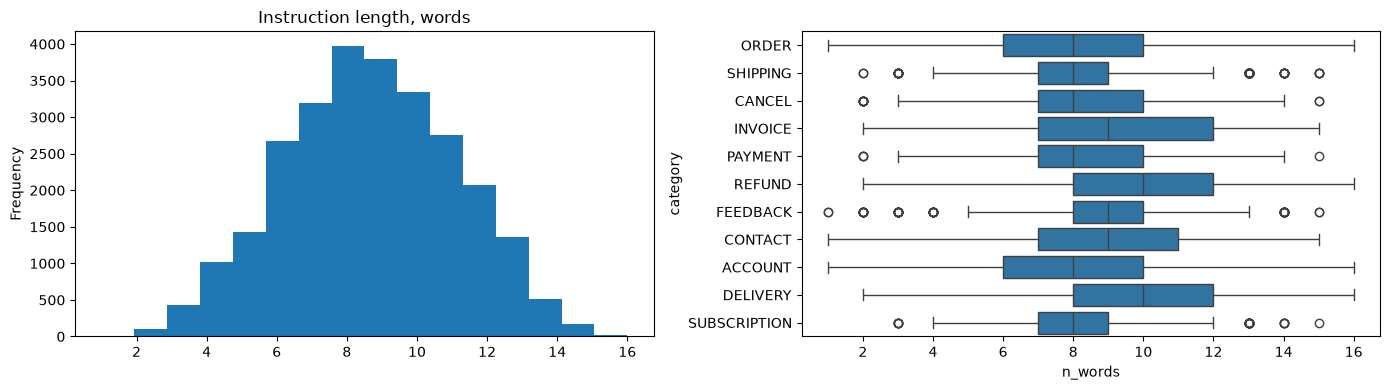

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df["n_words"].plot.hist(bins=16, ax=ax[0], title="Instruction length, words")
sns.boxplot(data=df, x="n_words", y="category", ax=ax[1])
plt.tight_layout()
plt.show()

Let's see what the instruction with 1-2 words are.

In [32]:
df.loc[df["n_words"] <= 2, ["instruction", "intent", "flags"]].sample(20, random_state=42)

,instruction,intent,flags
3719,withdrawal fee,check_cancellation_fee,BL
15202,getting invoice,get_invoice,BK
15087,get invoice,get_invoice,BK
10332,creating user,create_account,BK
9025,contactingassistant,contact_human_agent,BLZ
22443,review,review,BK
22116,leave review,review,BK
9665,contact somebodh,contact_human_agent,BLZ
1076,update purchase00004587345,change_order,BLZ
83,cancelling order,cancel_order,BK


We can see, that most of the requests contains keywords (see K flag). Often instruction means basic action, such as review, cancel order and other. But there is instruction without K flag. For example, people can use synonym (withdrawal -> cancellation). Some also contain typos (Z: “contactingassistant”, “contact somebodh”). Typos motivate character n-grams in addition to word n-grams; synonyms are where a pretrained transformer should help. Move on to placeholder.

In [ ]:
has_ph = df["instruction"].str.contains(r"\{\{.+?\}\}")
print(f"Rows with placeholders: {has_ph.mean():.1%}")

ph = (
    # it allows as to capture placeholders like that:
    # ship {{Order Number}} to {{Delivery City}} -> [Order_Number, Delivery_City]
    df.assign(placeholder=df["instruction"].str.findall(r"\{\{(.+?)\}\}"))
    .explode("placeholder")
    .dropna(subset=["placeholder"])
)
ph["placeholder"].value_counts().head(15)

Rows with placeholders: 24.8%


placeholder
Order Number        2907
Account Type        1011
Person Name          887
Account Category     822
Refund Amount        624
Currency Symbol      372
Delivery City        234
Delivery Country     177
Invoice Number         8
Name: count, dtype: int64

Almost 25 percents of rows has placeholders. The most frequent placeholders are Order Number, Account Type, Person Name, Account Category. Let's see how often all of classes of placeholders consists in any kind of intent.

In [37]:
ct = pd.crosstab(ph["placeholder"], ph["intent"])
pd.concat(
    [
        (ct.max(axis=1) / ct.sum(axis=1)).rename("top_intent_share"),
        ct.idxmax(axis=1).rename("top_intent"),
        ct.sum(axis=1).rename("rows"),
    ],
    axis=1,
).sort_values("top_intent_share", ascending=False).head(15)

,top_intent_share,top_intent,rows
placeholder,,,
Delivery Country,1.000000,delivery_options,177
Delivery City,1.000000,delivery_options,234
Refund Amount,0.685897,track_refund,624
Invoice Number,0.625000,get_invoice,8
Currency Symbol,0.615591,track_refund,372
Person Name,0.506201,get_invoice,887
Order Number,0.334709,cancel_order,2907
Account Type,0.282888,delete_account,1011
Account Category,0.265207,switch_account,822


24.8% of requests contain template placeholders. Most of them point to a category rather than an intent (e.g. {{Order Number}} is spread across several ORDER intents, top-intent share 0.33). Exceptions: {{Delivery City}} / {{Delivery Country}} appear only in delivery_options (share 1.0, ~400 rows), and refund placeholders mostly in track_refund (~0.65). Real user requests would contain actual values instead of placeholders, so entity normalisation is needed before serving.

In [38]:
for intent in ["cancel_order", "change_order", "check_invoice", "get_invoice"]:
    print(f"--- {intent}")
    for text in df.loc[df["intent"] == intent, "instruction"].sample(3, random_state=42):
        print("   ", text)

--- cancel_order
    I cannot afford purchase {{Order Number}}
    I have bought some item, I have to cancel order {{Order Number}}
    I do not want this item, cancel order {{Order Number}}
--- change_order
    I have to delete several items from purchase {{Order Number}}
    updating purchase {{Order Number}}
    update purchase00123842
--- check_invoice
    I need assistance to take a quick look at bill #85632
    hepp seeing the bill from {{Person Name}}
    how do I check my bill from {{Person Name}}?
--- get_invoice
    i have got to get bill #37777 how to do it
    i do not know what i need to do to get my invoice #85632
    assistance to get my bills from {{Person Name}}


Entities are anonymised inconsistently: some appear as placeholders ({{Invoice Number}}, 8 rows), others as literal values (#85632, purchase00123842). Both need to be normalised to a single <num> token.

## Flags
Let's analyze how many we have any kind of flags

In [39]:
tags = list("BICNMLPQWKEZ")
pd.Series({t: df["flags"].str.contains(t).mean() for t in tags}, name="share_of_rows").sort_values(ascending=False)

B    1.000000
L    0.897403
Q    0.333730
I    0.291716
Z    0.196710
M    0.183090
C    0.098467
K    0.082874
E    0.070036
P    0.049457
W    0.047931
N    0.017230
Name: share_of_rows, dtype: float64

Every row has tag B and 90% have L, so they are not useful as evaluation slices. The informative slices are Q (colloquial, 33%), Z (typos, 20%) and K (keyword mode, 8%); they are used for slice-level metrics. N (negation, 1.7%) is too small for a stable metric.